# Tutorial: GION light-cone halo catalogues

This notebook shows how to read the GION light-cone halo catalogues, select massive halos, compute their redshifts and plot their positions.

**Before running:** download the halo shell used here, `S100` ($0.236 < z < 0.314$; 216 files, 27.9 GB), with [`download_halo.sh`](download_halo.sh):

```sh
sh download_halo.sh S100
```

The files are saved in `lc_halo_props/S100/`. The redshift range of each shell is listed in the [README](README.md) and in [`z_halo.txt`](z_halo.txt).

## Setup

The catalogues are stored in HDF5 format, which we read with `h5py`. We also use `astropy` to convert comoving distances to redshifts.

In [1]:
import numpy as np
import h5py
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import astropy.units as u
from astropy.cosmology import FlatLambdaCDM

## Inspecting a file

The light cone is divided into non-overlapping spherical shells centred on the observer, one directory per shell (`S080`–`S103`). Each shell is split into `Nfile` files, `halos.<i>.h5`.

Every file has a `Header` group, whose attributes describe the shell and the cosmology, and a `Subhalo` group containing the halo properties. The columns follow [MPI-Rockstar](https://github.com/Tomoaki-Ishiyama/mpi-rockstar/); see that repository for the definition of each column. Positions are comoving, in $h^{-1} \, \mathrm{Mpc}$, with the observer at the origin, and masses are in $h^{-1} \, M_\odot$.

Let's open the first file of `S100` and list its contents.

In [2]:
halodir = 'S100'

with h5py.File(f'lc_halo_props/{halodir}/halos.0.h5', 'r') as f:
    print(f.keys())
    print(f['Header'].attrs.keys())

    print('Header information:')
    for key, value in f['Header'].attrs.items():
        print(f'  {key}: {value}')

    print('Halo information:')
    for key, dset in f['Subhalo'].items():
        print(f'  {key}: shape {dset.shape}, dtype {dset.dtype}')

    header = dict(f['Header'].attrs)

Nfile = header['Nfile']
ComovingDistanceMin = header['ComovingDistanceMin']  # [Mpc/h]
ComovingDistanceMax = header['ComovingDistanceMax']  # [Mpc/h]
Omega_m = header['Omega_m']
h = header['h']

<KeysViewHDF5 ['Header', 'Shape', 'Subhalo']>
<KeysViewHDF5 ['Bounds', 'BoxSize', 'ComovingDistanceBuffer', 'ComovingDistanceMax', 'ComovingDistanceMin', 'Nfile', 'NumberHalos', 'Omega_L', 'Omega_m', 'ParticleMass', 'Redshift', 'ScaleFactor', 'TotalNumberHalos', 'h']>
Header information:
  Bounds: [-874.76098633 -583.17399089 -874.76098633 -583.17399089 -874.76098633
 -583.17399089]
  BoxSize: 1749.52197265625
  ComovingDistanceBuffer: 10.0
  ComovingDistanceMax: 869.761
  ComovingDistanceMin: 667.66
  Nfile: 216
  NumberHalos: 0
  Omega_L: 0.6841999888420105
  Omega_m: 0.3158000111579895
  ParticleMass: 1275340544.0
  Redshift: 0.31239524483680725
  ScaleFactor: 0.7619655728340149
  TotalNumberHalos: 137434489
  h: 0.6732100248336792
Halo information:
  AngularMomentum: shape (0, 3), dtype float32
  BulkVelocity: shape (0, 3), dtype float32
  ChildLevel: shape (0,), dtype int32
  ChildRadius: shape (0,), dtype float32
  CoreVelocity: shape (0, 3), dtype float32
  DescendantID: shape (

## Converting comoving distance to redshift

The catalogues do not store halo redshifts, so we compute them from the comoving distance using the cosmology in the header. Instead of solving for the redshift of every halo, we tabulate the comoving distance on a fine redshift grid and invert it by interpolation, which is much faster for large catalogues.

> **Note:** The `Redshift` attribute in the header (and the corresponding `ScaleFactor`) is **not** the redshift of the shell or of its halos. It is a temporary value taken from the simulation snapshot, so do not use it. Always derive redshifts from the comoving distance as shown here.

In [3]:
cosmo = FlatLambdaCDM(H0=100.0 * h, Om0=Omega_m)

z_grid = np.linspace(0.0, 3.0, 30001)
chi_grid = cosmo.comoving_distance(z_grid).to_value(u.Mpc) * h  # [Mpc/h]

def chi_to_z(chi):
    # convert comoving distance [Mpc/h] to redshift
    return np.interp(chi, chi_grid, z_grid)

zmin, zmax = chi_to_z(ComovingDistanceMin), chi_to_z(ComovingDistanceMax)

In [4]:
print("Comoving distance range: [{:.2f}, {:.2f}] Mpc/h".format(ComovingDistanceMin, ComovingDistanceMax))
print("Redshift range: [{:.4f}, {:.4f}]".format(zmin, zmax))

Comoving distance range: [667.66, 869.76] Mpc/h
Redshift range: [0.2364, 0.3144]


## Loading massive halos

The halos of a shell are spread over `Nfile` files, and some files contain no halos (`NumberHalos = 0`). We loop over all files and keep only the positions and masses of massive halos with $M_\mathrm{vir} > 10^{14} \, h^{-1} \, M_\odot$.

In [5]:
Mvir_min = 1e14  # [Msun/h]

Position = []
Mass = []

for i in range(Nfile):
    with h5py.File(f'lc_halo_props/{halodir}/halos.{i}.h5', 'r') as f:
        if f['Header'].attrs['NumberHalos'] == 0:
            continue  # skip files with no halos
        Mass_ = f['Subhalo']['Mvir'][:]
        Position_ = f['Subhalo']['Position'][:]
        selected = Mass_ > Mvir_min
        Position.append(Position_[selected])
        Mass.append(Mass_[selected])

Position = np.concatenate(Position)
Mass = np.concatenate(Mass)
print("Number of loaded halos:", len(Mass))

Number of loaded halos: 27556


The redshift of each halo follows from its comoving distance.

In [6]:
Redshift = chi_to_z(np.linalg.norm(Position, axis=1))

## Plotting the halos

Now the catalogue is ready. Let's plot the positions of the massive halos projected onto the $x$–$y$ plane, coloured by redshift, with marker size increasing with mass. The dashed circles mark the inner and outer boundaries of the shell.

First, we define a linear mapping between $\log_{10} M_\mathrm{vir}$ and marker size, together with its inverse, which is used for the legend labels.

In [7]:
logMmin, logMmax = 14.0, 15.0
min_marker_size = 5    # marker size at logMmin
max_marker_size = 100  # marker size at logMmax

def mass_to_sizes(logM):
    return min_marker_size + (logM - logMmin) / (logMmax - logMmin) * (max_marker_size - min_marker_size)

def sizes_to_mass(s):
    return logMmin + (s - min_marker_size) / (max_marker_size - min_marker_size) * (logMmax - logMmin)

sizes = mass_to_sizes(np.log10(Mass))

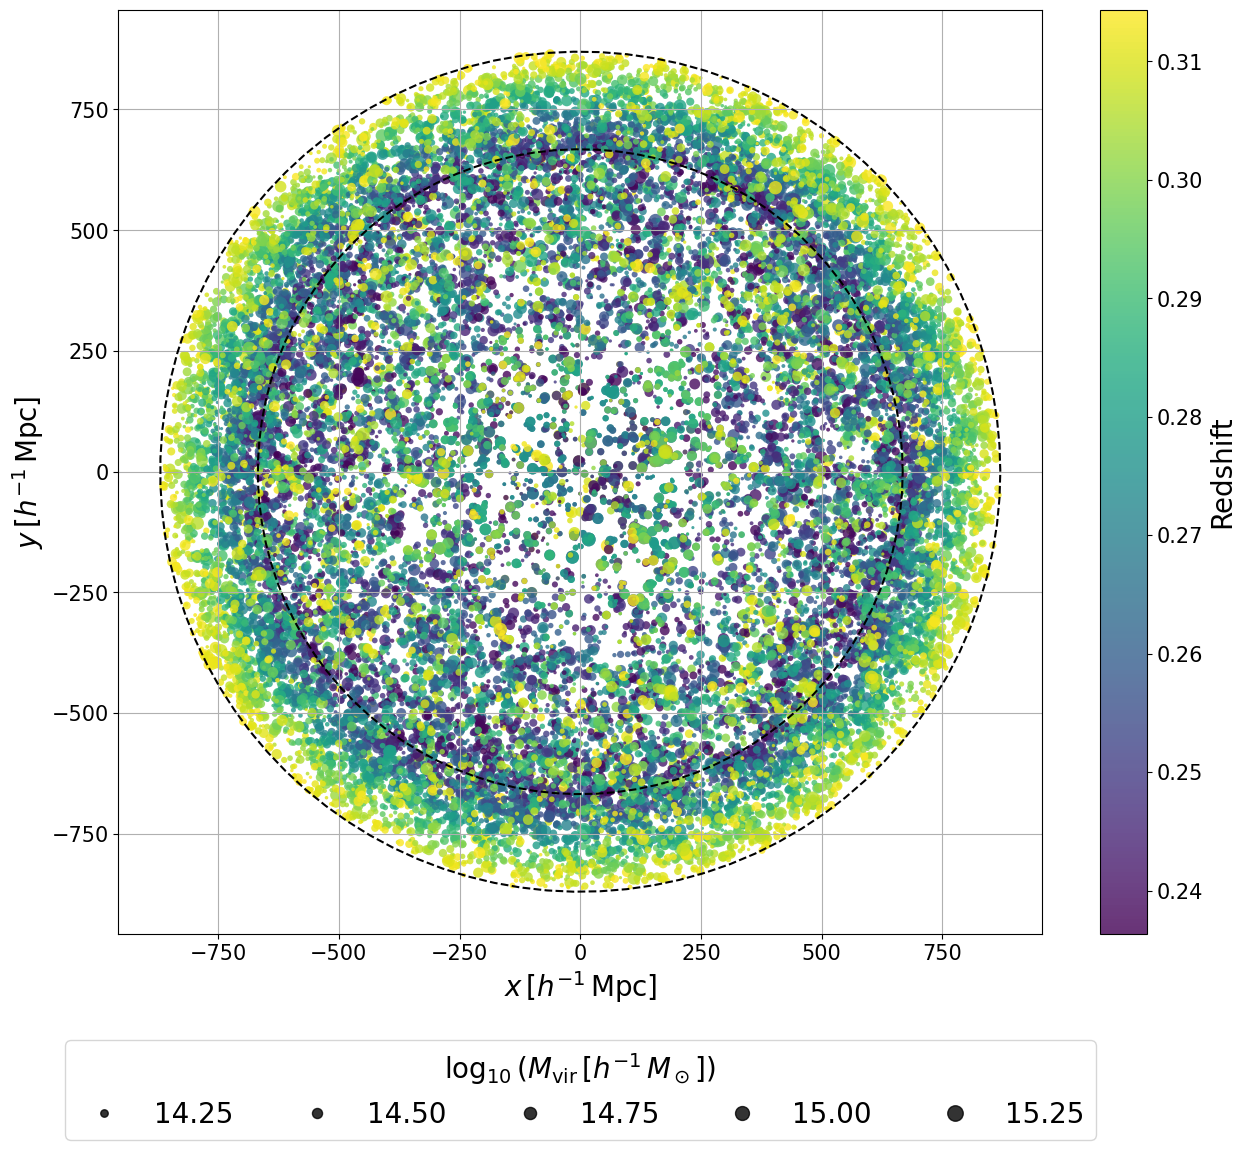

In [8]:
fontsize = 20
fig, ax = plt.subplots(figsize=(15, 12))

sc = ax.scatter(Position[:, 0], Position[:, 1], c=Redshift, s=sizes, cmap='viridis',
                norm=mcolors.Normalize(vmin=zmin, vmax=zmax), alpha=0.8, edgecolors='none')

# inner and outer boundaries of the shell
t = np.linspace(0.0, 2.0 * np.pi, 100)
for chi in (ComovingDistanceMin, ComovingDistanceMax):
    ax.plot(chi * np.cos(t), chi * np.sin(t), 'k--')

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("Redshift", fontsize=fontsize)
cbar.ax.tick_params(labelsize=15)

handles, labels = sc.legend_elements(prop="sizes", num=6, color='k', fmt="{x:.2f}", alpha=0.8,
                                     func=sizes_to_mass)
# place the legend below the axes so that it does not hide any halos
ax.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=len(handles), fontsize=fontsize,
          title=r"$\log_{10}(M_\mathrm{vir} \, [h^{-1} \, M_\odot])$", title_fontsize=fontsize)

ax.set_xlabel(r"$x \, [h^{-1} \, \mathrm{Mpc}]$", fontsize=fontsize)
ax.set_ylabel(r"$y \, [h^{-1} \, \mathrm{Mpc}]$", fontsize=fontsize)
ax.tick_params(axis='both', labelsize=15)
ax.set_aspect('equal', adjustable='box')
ax.grid()
plt.show()